# **Corrective RAG with Web Search Refinement**

![Web Search Refinement RAG Pipeline.png](<attachment:Web Search Refinement RAG Pipeline.png>)
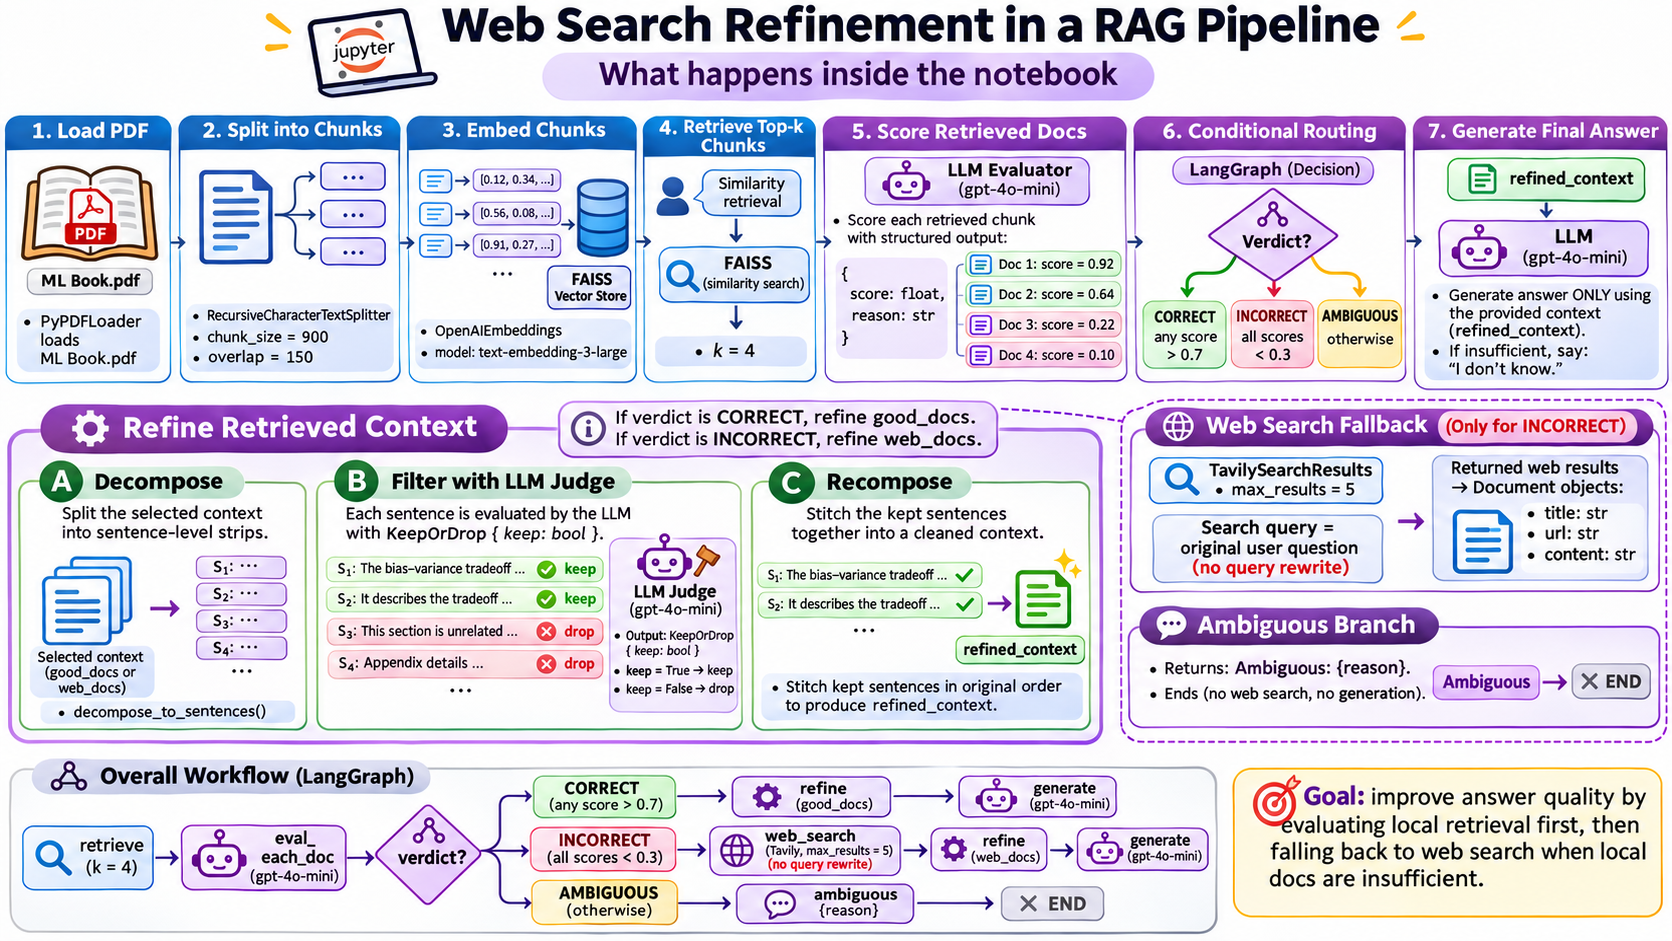


This notebook implements a **Corrective RAG pipeline using LangGraph, FAISS, GPT-4o-mini, and Tavily**. It evaluates retrieved documents and uses web search when local knowledge is insufficient.

## 1. Workflow

```text
User Question
      ↓
FAISS Retrieval (Top 4 Chunks)
      ↓
LLM Document Evaluator
      ↓
Conditional Routing
      │
      ├── CORRECT → Refine Local Documents
      │
      ├── INCORRECT → Tavily Web Search → Refine Web Results
      │
      └── AMBIGUOUS → Return Message → END
      ↓
Answer Generation
      ↓
Final Answer
```

## 2. Main Components

| Component | Description |
|---|---|
| **PDF Loader** | Loads `ML Book.pdf` using `PyPDFLoader`. |
| **FAISS** | Stores document embeddings (`text-embedding-3-large`) and retrieves the top 4 chunks. |
| **Document Evaluator** | Uses GPT-4o-mini to assign relevance scores between 0 and 1. |
| **Conditional Router** | Selects the next node based on document scores. |
| **Tavily Search** | Retrieves up to 5 web results when local retrieval is classified as INCORRECT. |
| **Refinement** | Decomposes text into sentences, filters irrelevant sentences, and recomposes useful context. |
| **Answer Generator** | Generates an answer using only the refined context. |

## 3. Evaluation Rules

- **CORRECT:** At least one document scores > 0.7. Keep documents scoring > 0.3.
- **INCORRECT:** All documents score < 0.3. Trigger Tavily web search.
- **AMBIGUOUS:** Otherwise, return an ambiguity message.

## 4. Key Takeaway

Unlike basic RAG, this pipeline **evaluates retrieval quality before generating an answer** and can recover from poor local retrieval using web search.

**Limitations:** The current implementation has no query rewriting, no web-result quality evaluation, and no automatic retry for ambiguous results. Web search uses the original question directly.

In [1]:
from typing import List, TypedDict, Literal
from pydantic import BaseModel
import re

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
import os


from langchain_community.tools.tavily_search import TavilySearchResults
load_dotenv()

api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("BASE_URL")

C:\Users\meisa\AppData\Local\Temp\ipykernel_68336\2209193786.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader
W1102 09:33:43.206000 68336 Lib\site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1102 09:33:43.440000 68336 Lib\site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


In [2]:
docs = (
    PyPDFLoader("./documents/ML Book.pdf").load()
)

In [3]:
chunks = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150).split_documents(docs)
for d in chunks:
    d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")

In [4]:
#embeddings = OpenAIEmbeddings(model="text-embedding-3-large")

from langchain_huggingface import HuggingFaceEmbeddings

hf_embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')

vector_store = FAISS.from_documents(chunks, hf_embeddings)
retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})

In [5]:
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0, api_key=api_key, base_url=base_url)

In [6]:
UPPER_TH = 0.7
LOWER_TH = 0.3

In [7]:
class State(TypedDict):

    question: str
    docs: List[Document]

    good_docs: List[Document]
    verdict: str
    reason: str

    strips: List[str]
    kept_strips: List[str]
    refined_context: str

    web_docs: List[Document] 
    
    answer: str

In [8]:
def retrieve_node(state: State) -> State:
    q = state["question"]
    return {"docs": retriever.invoke(q)}

In [9]:
# -----------------------------
# Score-based doc evaluator
# -----------------------------
class DocEvalScore(BaseModel):
    score: float
    reason: str

doc_eval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a strict retrieval evaluator for RAG.\n"
            "You will be given ONE retrieved chunk and a question.\n"
            "Return a relevance score in [0.0, 1.0].\n"
            "- 1.0: chunk alone is sufficient to answer fully/mostly\n"
            "- 0.0: chunk is irrelevant\n"
            "Be conservative with high scores.\n"
            "Also return a short reason.\n"
            "Output JSON only.",
        ),
        ("human", "Question: {question}\n\nChunk:\n{chunk}"),
    ]
)

doc_eval_chain = doc_eval_prompt | llm.with_structured_output(DocEvalScore)

def eval_each_doc_node(state: State) -> State:
    q = state["question"]
    scores: List[float] = []
    good: List[Document] = []

    for d in state["docs"]:
        out = doc_eval_chain.invoke({"question": q, "chunk": d.page_content})
        scores.append(out.score)

        if out.score > LOWER_TH:
            good.append(d)

    if any(s > UPPER_TH for s in scores):
        return {
            "good_docs": good,
            "verdict": "CORRECT",
            "reason": f"At least one retrieved chunk scored > {UPPER_TH}.",
        }

    if len(scores) > 0 and all(s < LOWER_TH for s in scores):
        why = "No chunk was sufficient."
        return {
            "good_docs": [],
            "verdict": "INCORRECT",
            "reason": f"All retrieved chunks scored < {LOWER_TH}. {why}",
        }

    why = "Mixed relevance signals."
    return {
        "good_docs": good,
        "verdict": "AMBIGUOUS",
        "reason": f"No chunk scored > {UPPER_TH}, but not all were < {LOWER_TH}. {why}",
    }


In [ ]:
# -----------------------------
# Sentence-level DECOMPOSER
# -----------------------------
def decompose_to_sentences(text: str) -> List[str]:
    text = re.sub(r"\s+", " ", text).strip()
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [s.strip() for s in sentences if len(s.strip()) > 20]

# -----------------------------
# FILTER (LLM judge)
# -----------------------------
class KeepOrDrop(BaseModel):
    keep: bool

filter_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a relevance filter.\n"
            "Return keep=true if the sentence contains relevant information, news, or context related to the question.\n"
            "Use ONLY the sentence. Output JSON only.",
        ),
        ("human", "Question: {question}\n\nSentence:\n{sentence}"),
    ]
)

filter_chain = filter_prompt | llm.with_structured_output(KeepOrDrop)

# -----------------------------
# REFINING (Decompose -> Filter -> Recompose)
# -----------------------------
def refine(state: State) -> State:
    q = state["question"]

    if state.get("verdict") == "CORRECT":
        context = "\n\n".join(d.page_content for d in state["good_docs"]).strip()
    else:
        context = "\n\n".join(d.page_content for d in state["web_docs"]).strip()

    strips = decompose_to_sentences(context)

    kept: List[str] = []
    for s in strips:
        if filter_chain.invoke({"question": q, "sentence": s}).keep:
            kept.append(s)

    refined_context = "\n".join(kept).strip()

    return {
        "strips": strips,
        "kept_strips": kept,
        "refined_context": refined_context,
    }


In [17]:
# -----------------------------
# Web search (Iteration 4)
# Assumption: web search does not fail (no fail node in this branch)
# -----------------------------
tavily = TavilySearchResults(max_results=5)

def web_search_node(state: State) -> State:

    q = state["question"]  # no query rewrite
    results = tavily.invoke({"query": q})  # no knowledge selection

    web_docs = []
    for r in results or []:

        title = r.get("title", "")
        url = r.get("url", "")
        content = r.get("content", "") or r.get("snippet", "")
        
        text = f"TITLE: {title}\nURL: {url}\nCONTENT:\n{content}"

        web_docs.append(Document(page_content=text, metadata={"url": url, "title": title}))

    return {"web_docs": web_docs}


In [23]:
tavily.invoke("AI news in 2026")

[{'title': 'Latest Ai News March 2026 Ai News',
  'url': 'https://www.instagram.com/popular/latest-ai-news-march-2026-ai-news',
  'content': 'In 2026, Artificial Intelligence has moved past the "experimental" phase of 2023–2024 and is now defined by Agentic AI—systems that don\'t just answer questions but independently execute complex, multi-step tasks. Here is the state of AI as of early 2026: 1. The Rise of "Agentic" AI The biggest shift this year is the move from AI as a "chatbot" to AI as a "digital coworker." Multi-Agent Systems Self-Verification 2. Major Industry Moves The competitive landscape has consolidated into a few "super-ecosystems": xAI & SpaceX Merger Physical AI Small Teams, Big Impact 3. Key Technology Trends On-Device AI The "Context" Breakthrough English as a Programming Language 4. Regulation & Ethics The "Wild West" era of AI has ended with the full implementation of major laws: EU AI Act Enforcement [...] browser autonomously. Multimodal Reasoning: AI is no longe

In [18]:
answer_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a helpful ML tutor. Answer ONLY using the provided context.\n"
            "If the context is empty or insufficient, say: 'I don't know.'",
        ),
        ("human", "Question: {question}\n\nRefined context:\n{refined_context}"),
    ]
)

def generate(state: State) -> State:
    out = (answer_prompt | llm).invoke(
        {"question": state["question"], "refined_context": state["refined_context"]}
    )
    return {"answer": out.content}


In [19]:
def ambiguous_node(state: State) -> State:
    return {"answer": f"Ambiguous: {state['reason']}"}

def route_after_eval(state: State) -> str:
    if state["verdict"] == "CORRECT":
        return "refine"
    elif state["verdict"] == "INCORRECT":
        return "web_search"
    else:
        return "ambiguous"

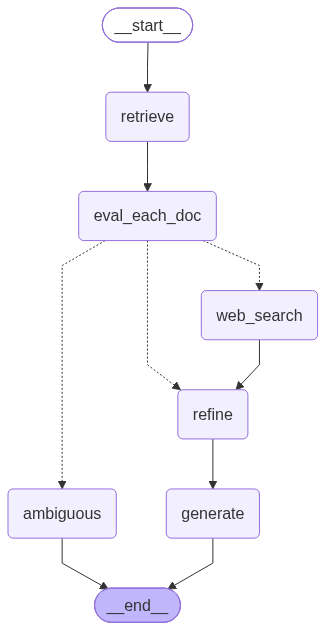

In [20]:
# -----------------------------
# Graph
# -----------------------------
g = StateGraph(State)

g.add_node("retrieve", retrieve_node)
g.add_node("eval_each_doc", eval_each_doc_node)
g.add_node("web_search", web_search_node)
g.add_node("refine", refine)          # uses verdict to pick good_docs vs web_docs
g.add_node("generate", generate)
g.add_node("ambiguous", ambiguous_node)

# flow
g.add_edge(START, "retrieve")
g.add_edge("retrieve", "eval_each_doc")

# route after evaluation
g.add_conditional_edges(
    "eval_each_doc",
    route_after_eval,
    {
        "refine": "refine",          # CORRECT -> refine (good_docs)
        "web_search": "web_search",  # INCORRECT -> web_search
        "ambiguous": "ambiguous",    # AMBIGUOUS -> end (your current choice)
    },
)

# ✅ key change: web_search now goes through refine
g.add_edge("web_search", "refine")    # INCORRECT -> refine (web_docs)
g.add_edge("refine", "generate")      # CORRECT/INCORRECT -> generate

g.add_edge("generate", END)
g.add_edge("ambiguous", END)

app = g.compile()
app

In [24]:
llm.invoke("test")

AIMessage(content="It looks like you're testing the system! How can I assist you today?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 8, 'total_tokens': 23, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}, 'latency_checkpoint': {'service_ttft_ms': 499, 'user_visible_ttft_ms': 373, 'pre_inference_ms': 126, 'service_tbt_ms': 14, 'service_ttlt_ms': 702, 'engine_ttft_ms': 31, 'engine_ttlt_ms': 164, 'engine_tbt_ms': 8}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_4b2adf74ff', 'id': 'chatcmpl-EfhMAsuvfsdcFq2ee2rxIcJ6UNprs', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a19b4a-8cfd-78d3-b0e2-9e69b07e72c7-0', tool_calls=[], invalid_tool_calls=[], usage_met

In [26]:
res = app.invoke(
    {
        "question": "AI news from the last month",
        "docs": [],
        "good_docs": [],
        "verdict": "",
        "reason": "",
        "strips": [],
        "kept_strips": [],
        "refined_context": "",
        "web_docs": [],   # ✅ added
        "answer": "",
    }
)

print("VERDICT:", res["verdict"])
print("REASON:", res["reason"])
print("\nOUTPUT:\n", res["answer"])


VERDICT: INCORRECT
REASON: All retrieved chunks scored < 0.3. No chunk was sufficient.

OUTPUT:
 In September 2026, Google announced several significant AI updates, including the launch of Gemini 4 Argon, which features advanced reasoning capabilities for complex tasks. Other notable releases included Gemini 3.8 Flash and Gemini 3.8 Live, as well as the introduction of Googlebook for pre-order and the Gemini app for Windows. Major scientific milestones were also achieved, such as mapping human DNA with AlphaGenome Atlas and tracking global methane from space. Additionally, Project Suncatcher was launched to test machine learning hardware in orbit.

In October 2026, Google re-entered the frontier race, while Meta and Mistral also made notable advancements. OpenAI and Anthropic focused on making AI agents more affordable and useful, with Anthropic filing to go public. The PHP2Shell disclosure highlighted how AI can assist in addressing software vulnerabilities. AI-generated mathematical 

In [ ]:
# Bias variance tradeoff
# AI news from last week
# What are attention mechanisms and why are they important in current models?